# Denoising a Signal Using the FFT

## Problem

Given a time-domain signal $f(t)$ corrupted by additive noise,

$$
f(t) = f_{\text{clean}}(t) + \eta(t),
$$

recover an approximation to $f_{\text{clean}}(t)$.

## Algorithm

1. **Compute the FFT.** Transform the noisy signal into the frequency domain:

$$
\hat{f}(k) = \text{FFT}\{f(t)\}
$$

2. **Estimate the Power Spectral Density (PSD).** For each frequency bin $k$:

$$
P(k) = \frac{|\hat{f}(k)|^2}{n}
$$

   where $n$ is the number of samples. Genuine signal components produce tall, narrow spikes in $P(k)$; broadband noise spreads energy roughly uniformly across all frequencies.

3. **Threshold the PSD.** Choose a cutoff $\tau$ and keep only frequencies whose power exceeds it:

$$
\text{mask}(k) =
\begin{cases}
1 & \text{if } P(k) > \tau \\
0 & \text{otherwise}
\end{cases}
$$

4. **Zero out noisy coefficients.** Apply the mask to the Fourier coefficients:

$$
\hat{f}_{\text{filt}}(k) = \text{mask}(k) \cdot \hat{f}(k)
$$

5. **Inverse FFT.** Transform back to the time domain to obtain the denoised signal:

$$
f_{\text{filt}}(t) = \text{IFFT}\{\hat{f}_{\text{filt}}(k)\}
$$

## Why it works

The key insight is that a signal composed of a few sinusoids concentrates its energy at specific frequencies (sharp peaks in the PSD), while white noise spreads energy uniformly. Thresholding the PSD cleanly separates signal from noise — this is essentially a **brick-wall band-pass filter** in the frequency domain.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [16, 12]
plt.rcParams.update({'font.size': 18})

# Create a simple signal with two frequencies
dt = 0.001
t = np.arange(0,1,dt)
f = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*120*t) # Sum of 2 frequencies
f_clean = f
f = f + 2.5*np.random.randn(len(t))              # Add some noise

In [7]:


## Compute the Fast Fourier Transform (FFT)

n = len(t)
fhat = np.fft.fft(f,n)                     # Compute the FFT
PSD = fhat * np.conj(fhat) / n             # Power spectrum (power per freq)
freq = (1/(dt*n)) * np.arange(n)           # Create x-axis of frequencies in Hz
L = np.arange(1,np.floor(n/2),dtype='int') # Only plot the first half of freqs



In [ ]:
## Use the PSD to filter out noise
indices = PSD > 100       # Find all freqs with large power. Creates indices for freqs we want to keep and zero out all others
PSDclean = PSD * indices  # Zero out all others.
fhat = indices * fhat     # Zero out small Fourier coeffs. in Y
ffilt = np.fft.ifft(fhat) # Inverse FFT for filtered time signal

### Frequency-Domain Thresholding for Denoising

This code block removes noise by keeping only the frequency components with large power:

- `indices = PSD > 100` creates a boolean mask for frequencies where the power spectral density (PSD) is above a chosen threshold (here, 100). These are assumed to be the true signal frequencies.
- `PSDclean = PSD * indices` zeros out the PSD at all other frequencies (for plotting/diagnostics).
- `fhat = indices * fhat` sets the Fourier coefficients to zero everywhere except at the strong signal frequencies.
- `ffilt = np.fft.ifft(fhat)` transforms the filtered coefficients back to the time domain, yielding a denoised signal that contains only the dominant frequency components.

This is a simple but effective way to separate signal from noise when the signal is sparse in the frequency domain.

In [9]:
## Shape checks
print(f"{'t':>10s}: {t.shape}")
print(f"{'f':>10s}: {f.shape}  (noisy signal)")
print(f"{'f_clean':>10s}: {f_clean.shape}  (clean signal)")
print(f"{'fhat':>10s}: {fhat.shape}  dtype={fhat.dtype}")
print(f"{'PSD':>10s}: {PSD.shape}  dtype={PSD.dtype}")
print(f"{'freq':>10s}: {freq.shape}")
print(f"{'L':>10s}: {L.shape}  (first-half indices)")
print(f"{'indices':>10s}: {indices.shape}  dtype={indices.dtype}")
print(f"{'PSDclean':>10s}: {PSDclean.shape}")
print(f"{'ffilt':>10s}: {ffilt.shape}  dtype={ffilt.dtype}")

         t: (1000,)
         f: (1000,)  (noisy signal)
   f_clean: (1000,)  (clean signal)
      fhat: (1000,)  dtype=complex128
       PSD: (1000,)  dtype=complex128
      freq: (1000,)
         L: (499,)  (first-half indices)
   indices: (1000,)  dtype=bool
  PSDclean: (1000,)
     ffilt: (1000,)  dtype=complex128


/app/sreeram/datascience/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/app/sreeram/datascience/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


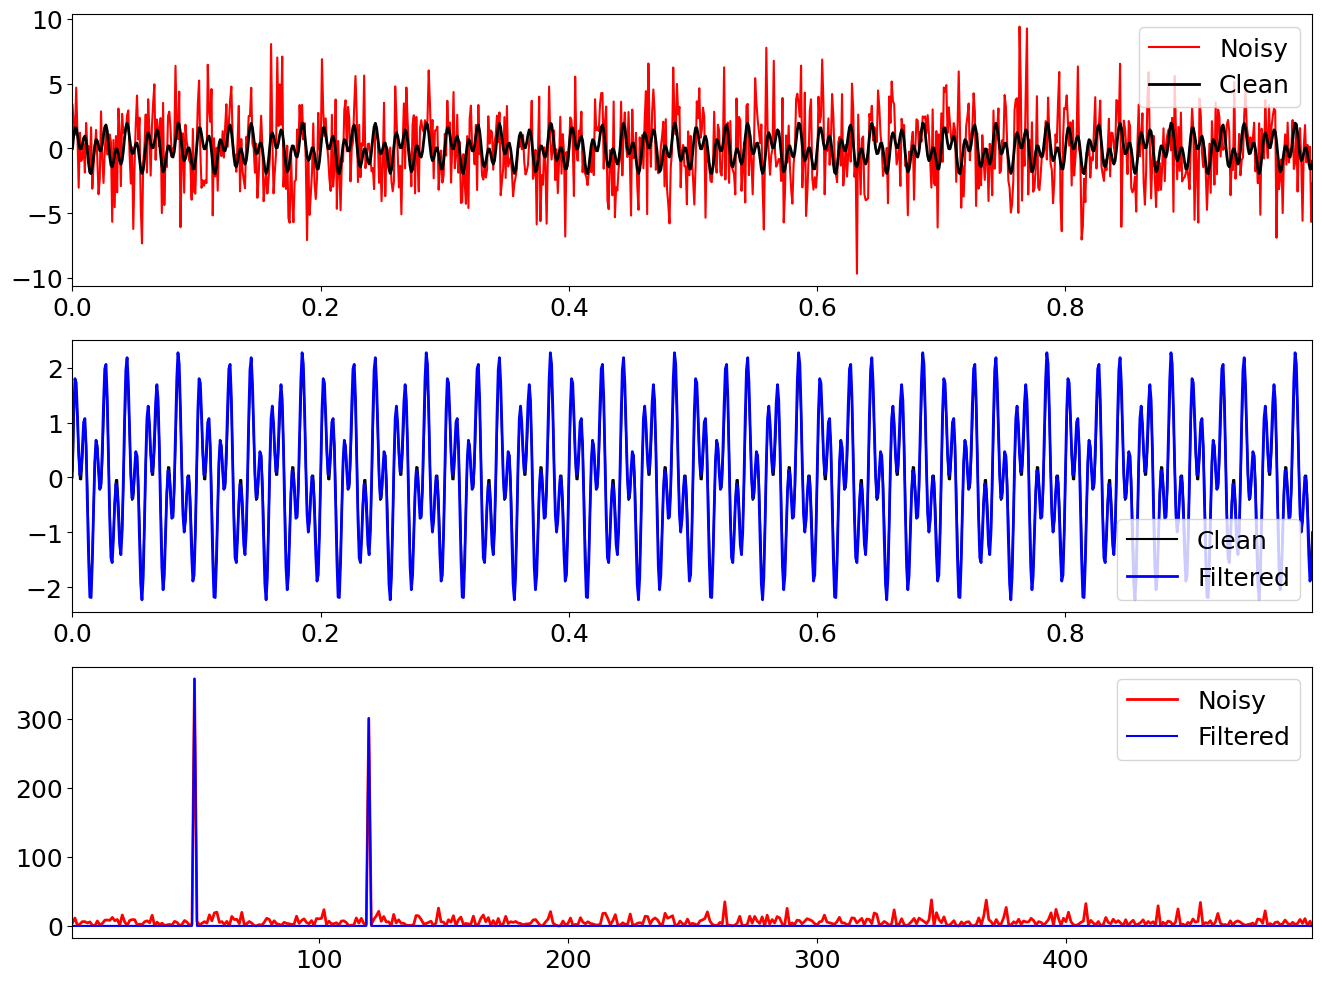

In [11]:


## Plots
fig,axs = plt.subplots(3,1)

plt.sca(axs[0])
plt.plot(t,f,color='r',linewidth=1.5,label='Noisy')
plt.plot(t,f_clean,color='k',linewidth=2,label='Clean')
plt.xlim(t[0],t[-1])
plt.legend()

plt.sca(axs[1])
plt.plot(t,f_clean,color='k',linewidth=1.5,label='Clean')
plt.plot(t,ffilt,color='b',linewidth=2,label='Filtered')
plt.xlim(t[0],t[-1])
plt.legend()

plt.sca(axs[2])
plt.plot(freq[L],PSD[L],color='r',linewidth=2,label='Noisy')
plt.plot(freq[L],PSDclean[L],color='b',linewidth=1.5,label='Filtered')
plt.xlim(freq[L[0]],freq[L[-1]])
plt.legend()

plt.show()

